In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("/Users/theerdhasjoy/BIA/ML/Dataset/perrin-freres-monthly-champagne-.csv")

In [3]:
df.head(5)

,Month,Perrin Freres monthly champagne sales millions ?64-?72
0,1964-01,2815.0
1,1964-02,2672.0
2,1964-03,2755.0
3,1964-04,2721.0
4,1964-05,2946.0


In [4]:
df.columns = ["Month", "Sales"]

df.head()


,Month,Sales
0,1964-01,2815.0
1,1964-02,2672.0
2,1964-03,2755.0
3,1964-04,2721.0
4,1964-05,2946.0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 107 entries, 0 to 106
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Month   106 non-null    str    
 1   Sales   105 non-null    float64
dtypes: float64(1), str(1)
memory usage: 2.6 KB


In [6]:
df.drop(106, axis= 0, inplace= True)

In [7]:
df.drop(105, axis= 0, inplace= True)

In [8]:
df.tail()

,Month,Sales
100,1972-05,4618.0
101,1972-06,5312.0
102,1972-07,4298.0
103,1972-08,1413.0
104,1972-09,5877.0


In [9]:
df['Month'] = pd.to_datetime(df['Month'])

In [10]:
df.head()

,Month,Sales
0,1964-01-01,2815.0
1,1964-02-01,2672.0
2,1964-03-01,2755.0
3,1964-04-01,2721.0
4,1964-05-01,2946.0


In [11]:
df.set_index('Month', inplace= True)

df.head()

,Sales
Month,
1964-01-01,2815.0
1964-02-01,2672.0
1964-03-01,2755.0
1964-04-01,2721.0
1964-05-01,2946.0


## Data Visualization

<Axes: xlabel='Month'>

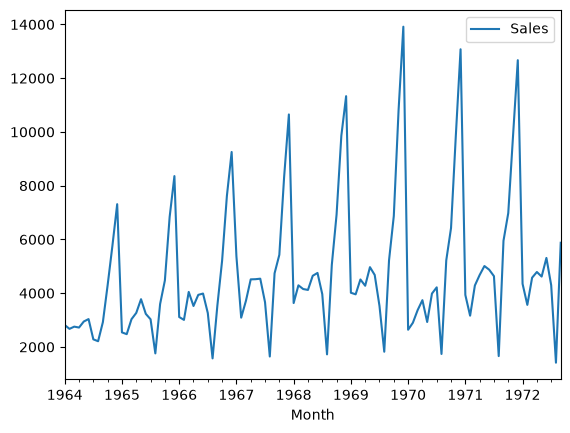

In [12]:
df.plot()

In [13]:
pip install statsmodels


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [15]:
from statsmodels.tsa.stattools import adfuller



In [16]:
df['Sales']

Month
1964-01-01    2815.0
1964-02-01    2672.0
1964-03-01    2755.0
1964-04-01    2721.0
1964-05-01    2946.0
               ...  
1972-05-01    4618.0
1972-06-01    5312.0
1972-07-01    4298.0
1972-08-01    1413.0
1972-09-01    5877.0
Name: Sales, Length: 105, dtype: float64

In [17]:
test_results = adfuller(df['Sales'])

/var/folders/y5/lf_stmcj5nv2hnzy3q1b5pb80000gn/T/ipykernel_19379/1102880549.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  test_results = adfuller(df['Sales'])


In [18]:
test_results

(-1.8335930563276222,
 0.3639157716602455,
 11,
 93,
 {'1%': np.float64(-3.502704609582561),
  '5%': np.float64(-2.8931578098779522),
  '10%': np.float64(-2.583636712914788)},
 np.float64(1478.4633060594724))

In [19]:
# H0 : It is non stationary
# H1 : It is stationary

def adfuller_test(sales):
    result = adfuller(sales)

    labels = ['ADF Test Statistics', 'p-value', '#Lags Used', 'Number of Observations used']

    if result[1] <= 0.05:
        print("strong evidence against null hyp")
    else:
        print("not stationary")

In [20]:
adfuller_test(df['Sales'])

not stationary


/var/folders/y5/lf_stmcj5nv2hnzy3q1b5pb80000gn/T/ipykernel_19379/1148853463.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(sales)


## Differencing

In [21]:
df['Sales']

Month
1964-01-01    2815.0
1964-02-01    2672.0
1964-03-01    2755.0
1964-04-01    2721.0
1964-05-01    2946.0
               ...  
1972-05-01    4618.0
1972-06-01    5312.0
1972-07-01    4298.0
1972-08-01    1413.0
1972-09-01    5877.0
Name: Sales, Length: 105, dtype: float64

In [ ]:
df['Sales'].shift(1)

Month
1964-01-01       NaN
1964-02-01    2815.0
1964-03-01    2672.0
1964-04-01    2755.0
1964-05-01    2721.0
               ...  
1972-05-01    4788.0
1972-06-01    4618.0
1972-07-01    5312.0
1972-08-01    4298.0
1972-09-01    1413.0
Name: Sales, Length: 105, dtype: float64

In [24]:
df['Sales First Difference'] = df['Sales'] - df['Sales'].shift(1)

In [25]:
df['Sales First Difference']

Month
1964-01-01       NaN
1964-02-01    -143.0
1964-03-01      83.0
1964-04-01     -34.0
1964-05-01     225.0
               ...  
1972-05-01    -170.0
1972-06-01     694.0
1972-07-01   -1014.0
1972-08-01   -2885.0
1972-09-01    4464.0
Name: Sales First Difference, Length: 105, dtype: float64

In [27]:
adfuller_test(df['Sales First Difference'].dropna())

strong evidence against null hyp


/var/folders/y5/lf_stmcj5nv2hnzy3q1b5pb80000gn/T/ipykernel_19379/1148853463.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(sales)


<Axes: xlabel='Month'>

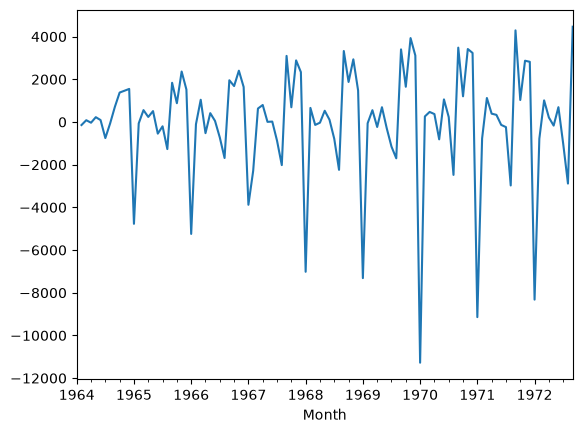

In [28]:
df['Sales First Difference'].plot()

## AR

In [35]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

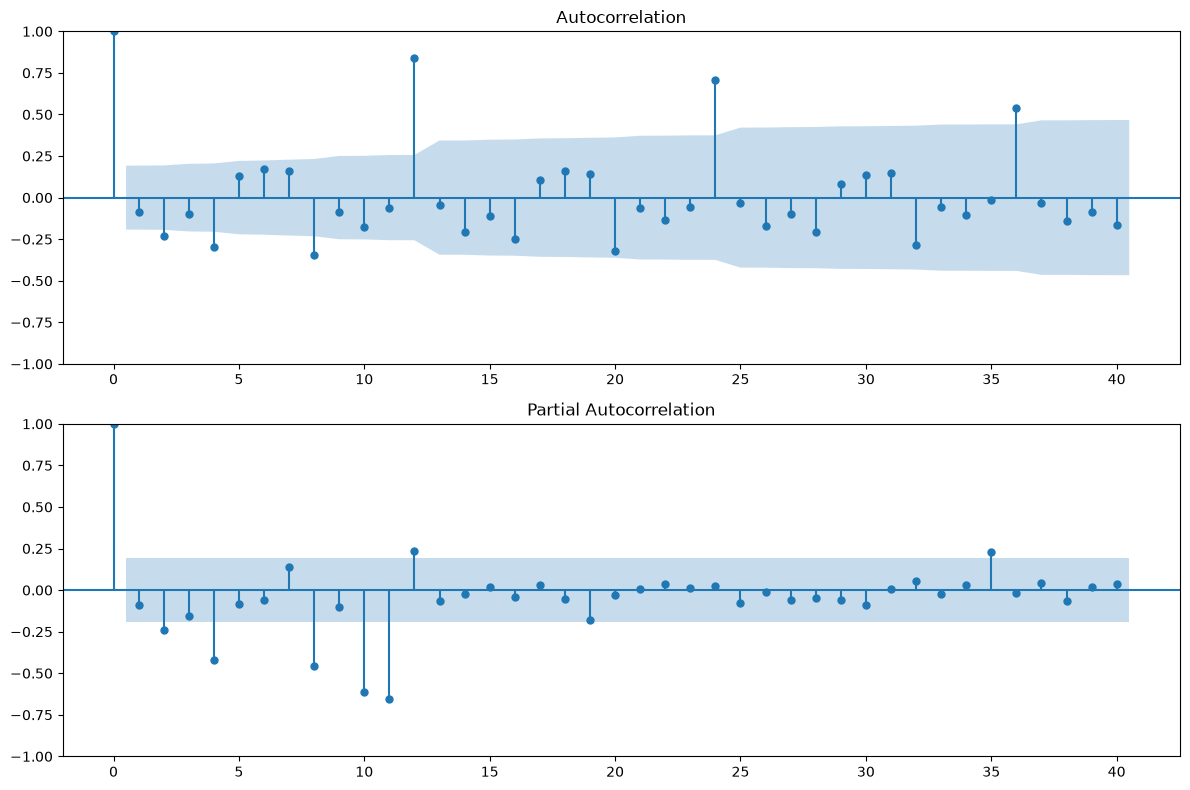

In [36]:
fig = plt.figure(figsize=(12, 8))

ax1 = fig.add_subplot(211)
plot_acf(df['Sales First Difference'].iloc[1:], lags=40, ax=ax1)

ax2 = fig.add_subplot(212)
plot_pacf(df['Sales First Difference'].iloc[1:], lags=40, ax=ax2)

plt.tight_layout()
plt.show()


In [37]:
df["Seasonal First Difference"] = df["Sales"]-df["Sales"].shift(12)

In [38]:
df.head(14)

,Sales,Sales First Difference,Seasonal First Difference
Month,,,
1964-01-01,2815.0,NaN,NaN
1964-02-01,2672.0,-143.0,NaN
1964-03-01,2755.0,83.0,NaN
1964-04-01,2721.0,-34.0,NaN
1964-05-01,2946.0,225.0,NaN
1964-06-01,3036.0,90.0,NaN
1964-07-01,2282.0,-754.0,NaN
1964-08-01,2212.0,-70.0,NaN
1964-09-01,2922.0,710.0,NaN


In [39]:
from statsmodels.tsa.arima.model import ARIMA

In [46]:
model = ARIMA(df['Sales'], order= (2,1,1))
model_fit = model.fit()

/Users/theerdhasjoy/BIA/bia_py_env/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<Axes: xlabel='Month'>

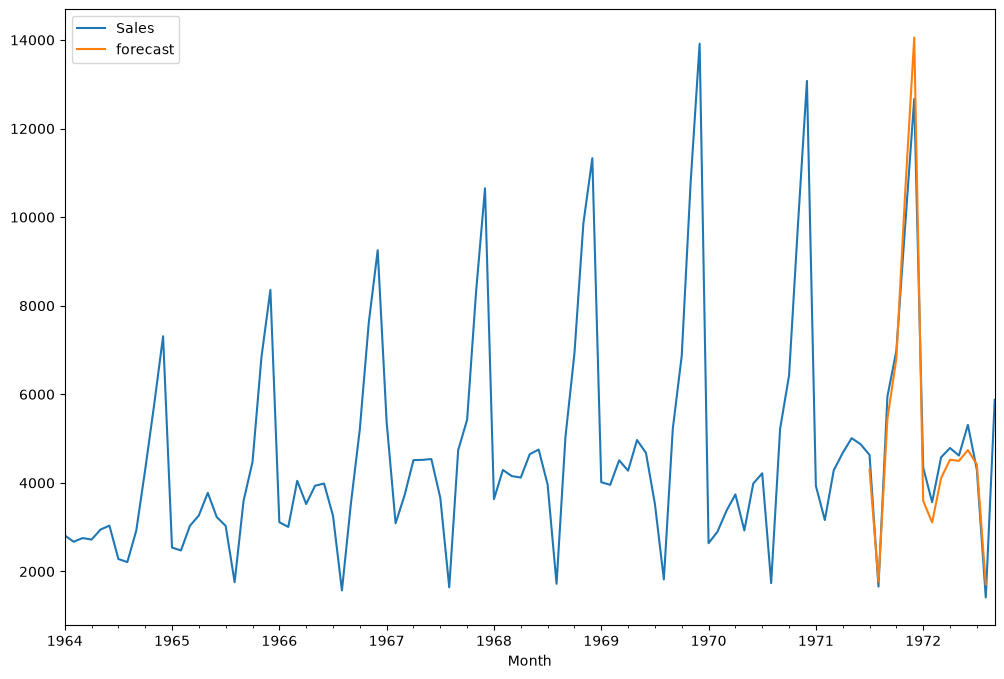

In [47]:
df['forecast'] = results.predict(start= 90, end= 103, dynamic= True)
df[['Sales','forecast']].plot(figsize= (12,8))

In [42]:
import statsmodels.api as sm

In [44]:
model=sm.tsa.statespace.SARIMAX(df['Sales'],order=(2, 1, 1),seasonal_order=(2,1,1,12))
results=model.fit()

/Users/theerdhasjoy/BIA/bia_py_env/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/theerdhasjoy/BIA/bia_py_env/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
